# 02 — Content-Based Recommender & the Taste Map

"This sounds like that": cosine similarity over standardized audio features.
Works for any track regardless of listening history, so it's the natural cold-start
layer for the hybrid built in notebook 04.

In [1]:
import sys
sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from src.data_loading import load_spotify_tracks, AUDIO_FEATURES
from src.content_based import ContentBasedRecommender

sns.set_theme(style='whitegrid')
tracks = load_spotify_tracks()
cbr = ContentBasedRecommender(tracks)
print(f'fit on {len(tracks):,} tracks, {len(AUDIO_FEATURES)} features')

fit on 77,134 tracks, 12 features


## Sanity check: does similarity actually find musically sensible neighbors?

In [2]:
seed = tracks.iloc[0]
print('Seed track:', seed['primary_artist'], '-', seed['track_name'], f"({seed['track_genre']})")
sims = cbr.similar_to(seed['track_id'], k=10)
sim_df = tracks.set_index('track_id').loc[[t for t, _ in sims], ['primary_artist', 'track_name', 'track_genre']]
sim_df['similarity'] = [s for _, s in sims]
sim_df

Seed track: Sam Smith - Unholy (feat. Kim Petras) (pop)


,primary_artist,track_name,track_genre,similarity
track_id,,,,
3DmW6y7wTEYHJZlLo1r6XJ,Becky G,Shower,latin,0.951420
3iiZjpzqX9It7OcPmnIJl3,Taladro,Duydum Ki,turkish,0.946236
100fdP6bcT8byvdEdAAcTJ,BadKidMacei,Super Gremlin Freestyle,kids,0.931018
1mo6pWcIXljy3y1Kju5JWG,Lil Peep,Moving On,emo,0.925815
0eH5Dws83TLClSm9hDDhwq,Pj Panda,Mary Had a Lil' lamb (Trap Remix),kids,0.923257
1eX7cu5TMlRlv5kDBFWaWI,Ryan Oakes,2AM,sad,0.922639
7JDWhC422Gtk1Bq0mL3OTC,Bea Miller,feel something,indie-pop,0.916664
55n9yjI6qqXh5F2mYvUc2y,ZAYN,I Don’t Wanna Live Forever (Fifty Shades Darker),pop,0.913827
1GbVo45KvYX3chroJggkIx,Martin Garrix,Oops,progressive-house,0.911684


In [3]:
print('Why the top match was recommended (smallest standardized feature gaps first):')
cbr.explain(seed['track_id'], sims[0][0])

Why the top match was recommended (smallest standardized feature gaps first):


key                 0.000000
mode                0.000000
time_signature      0.000000
instrumentalness    0.000093
loudness            0.032382
acousticness        0.055194
danceability        0.083684
liveness            0.094982
energy              0.220507
speechiness         0.317656
tempo               0.369433
valence             0.441210
dtype: float64

## The taste map

UMAP projection of the audio-feature space to 2D. If genres cluster visually, the
audio features are doing real discriminative work, not just noise.

In [4]:
# Subsample for a readable plot and reasonable UMAP runtime; full matrix used everywhere else.
sample = tracks.sample(n=min(15000, len(tracks)), random_state=42)
sample_idx = sample.index
sample_features = cbr.feature_matrix[sample_idx]

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(sample_features)
sample = sample.copy()
sample['umap_x'] = embedding[:, 0]
sample['umap_y'] = embedding[:, 1]

C:\Users\User\Desktop\MUSIC-RECOMMENDER\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


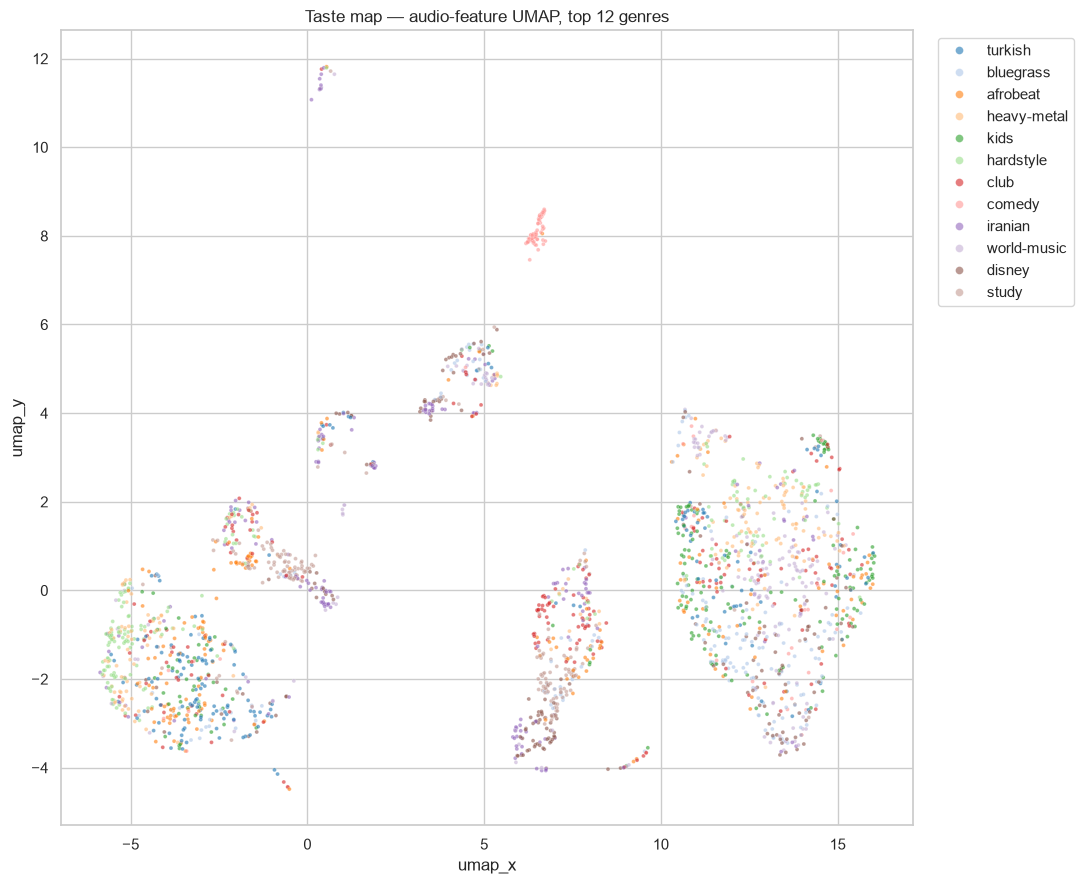

In [5]:
top_genres = sample['track_genre'].value_counts().head(12).index
plot_df = sample[sample['track_genre'].isin(top_genres)]

plt.figure(figsize=(11, 9))
sns.scatterplot(data=plot_df, x='umap_x', y='umap_y', hue='track_genre', s=8, alpha=0.6, palette='tab20')
plt.title('Taste map — audio-feature UMAP, top 12 genres')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', markerscale=2)
plt.tight_layout()
plt.savefig('../reports/figures/02_taste_map.png', dpi=150, bbox_inches='tight')
plt.show()

## Which features actually drive genre separation?

Hypothesis from planning: energy/valence/danceability dominate; acousticness/
instrumentalness carve out a separate acoustic/ambient region. Test it.

In [6]:
genre_feature_means = tracks.groupby('track_genre')[AUDIO_FEATURES].mean()
genre_feature_variance = genre_feature_means.var().sort_values(ascending=False)
print('Features with the most variance ACROSS genre means (i.e. most discriminative):')
genre_feature_variance

Features with the most variance ACROSS genre means (i.e. most discriminative):


tempo               77.237990
loudness            11.814753
key                  0.062530
acousticness         0.054213
instrumentalness     0.045075
energy               0.029058
valence              0.020953
mode                 0.014249
time_signature       0.012698
danceability         0.012619
liveness             0.005649
speechiness          0.005143
dtype: float64

## Popularity vs. audio features — is there a 'hit' signature?

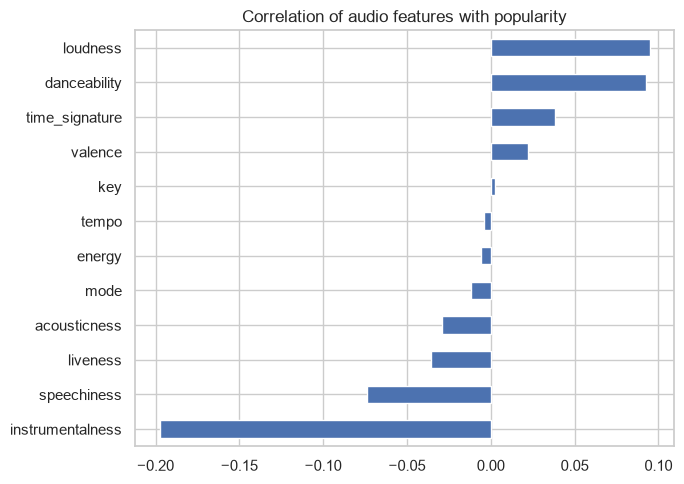

instrumentalness   -0.197522
speechiness        -0.073581
liveness           -0.035819
acousticness       -0.029304
mode               -0.011931
energy             -0.006083
tempo              -0.004297
key                 0.002787
valence             0.022183
time_signature      0.038472
danceability        0.092438
loudness            0.094661
Name: popularity, dtype: float64

In [7]:
corr = tracks[AUDIO_FEATURES + ['popularity']].corr()['popularity'].drop('popularity').sort_values()
corr.plot(kind='barh', figsize=(7, 5))
plt.title('Correlation of audio features with popularity')
plt.tight_layout()
plt.savefig('../reports/figures/02_popularity_correlation.png', dpi=150)
plt.show()
corr